In [1]:
import sys
sys.path.append("..")

from src.io_utils import load_csv_to_dataframe
from src.schemas import PathConfig

import pandas as pd

path_config = PathConfig()

path_config.ensure_directories()


In [2]:
df_credit = load_csv_to_dataframe(file_path=f"{path_config.input_dir}/creditcard.csv")

df_credit

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [3]:
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from imblearn.combine import SMOTEENN
from imblearn.combine import SMOTETomek
from imblearn.pipeline import Pipeline as PipelineImblearn
from imblearn.over_sampling import SMOTE

In [4]:
df_credit_copy = df_credit.copy()

In [5]:
X = df_credit_copy.drop('Class', axis=1)
y = df_credit_copy['Class']

# Split (helt opåverkad rådata)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [6]:
# Definiera kolumntransformering
preprocessor = ColumnTransformer(
    transformers=[
        ('scaler', RobustScaler(), ['Amount', 'Time']) # Skalar BARA Amount och Time
    ],
    remainder='passthrough' # Släpper igenom V1...V28 exakt som de är!
)

In [7]:
# Sätt ihop i en Pipeline
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1))
])

pipeline2 = PipelineImblearn(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(sampling_strategy= 0.1, random_state=42)),
    ("model", RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1))
])

smote = SMOTE(sampling_strategy= 0.1, random_state=42)
smote_smoteen = SMOTEENN(smote=smote, random_state=42)

pipeline3 = PipelineImblearn(steps=[
    ("preprocessor", preprocessor),
    ("hybrid_sampler", smote_smoteen),
    ("model", RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1))
])

pipeline4 = PipelineImblearn(steps=[
    ("preprocessor", preprocessor),
    ("hybrid_sampler", SMOTEENN(random_state=42)),
    ("model", RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1))
])

In [8]:
model_path_no_smote = path_config.model_dir / "credit_fraud_pipeline_untouched_dataset.joblib"

#Träna hela kedjan med en enda fit()-sats
if model_path_no_smote.exists():
    # Om filen finns -> ladda den
    pipe_no_smote = joblib.load(model_path_no_smote)

#Spara HELA pipelinen (scalern + modellen) till en enda fil
else:
    # Om filen inte finns -> träna modellen och spara den
    pipe_no_smote = pipeline.fit(X_train, y_train)
    joblib.dump(pipe_no_smote, model_path_no_smote)

In [9]:
model_path_smote = path_config.model_dir / "credit_fraud_pipeline_smote.joblib"

if model_path_smote.exists():
    pipe_smote = joblib.load(model_path_smote)

else:
    pipe_smote = pipeline2.fit(X_train, y_train)
    joblib.dump(pipe_smote, model_path_smote)

In [ ]:
model_path_smoteenn = path_config.model_dir / "credit_fraud_pipeline_smoteenn.joblib"

#takes the longest time.
if model_path_smoteenn.exists():
    pipe_smoteenn = joblib.load(model_path_smoteenn)

else:
    pipe_smoteenn = pipeline4.fit(X_train, y_train)
    joblib.dump(pipe_smoteenn, model_path_smoteenn)



In [11]:

model_path_smoteenn_smote = path_config.model_dir / "credit_fraud_pipeline_smoteenn_smote.joblib"

if model_path_smoteenn_smote.exists():
    pipe_smoteenn_smote = joblib.load(model_path_smoteenn_smote)

else:
    pipe_smoteenn_smote = pipeline3.fit(X_train, y_train)
    joblib.dump(pipe_smoteenn_smote, model_path_smoteenn_smote)



In [12]:
# Utvärdera på testdata (Pipelinen kör .transform() automatiskt på X_test)
y_probs_no_smote = pipe_no_smote.predict_proba(X_test)[:, 1]

In [13]:
y_probs_smote = pipe_smote.predict_proba(X_test)[:, 1]

In [14]:
y_probs_smoteenn = pipe_smoteenn.predict_proba(X_test)[:, 1]

In [15]:
y_probs_smoteenn_smote = pipe_smoteenn_smote.predict_proba(X_test)[:, 1]

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, auc

Area Under Precision-Recall Curve with full untouched dataset: 0.8599


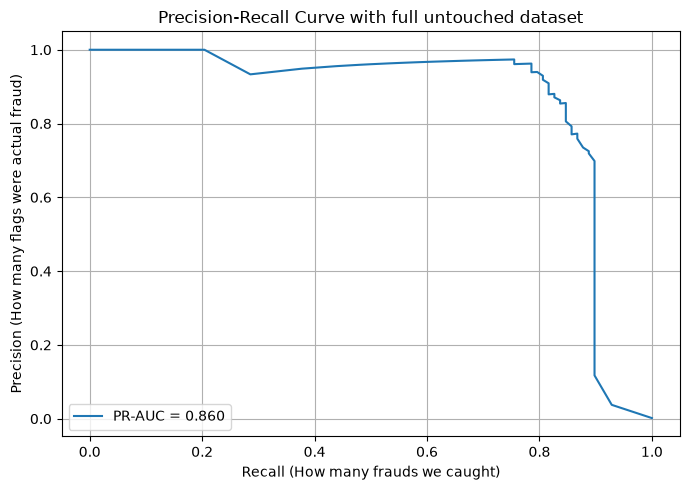

In [17]:
precision, recall, thresholds = precision_recall_curve(y_test, y_probs_no_smote)
pr_auc = auc(recall, precision)

print(f"Area Under Precision-Recall Curve with full untouched dataset: {pr_auc:.4f}")

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel('Recall (How many frauds we caught)')
plt.ylabel('Precision (How many flags were actual fraud)')
plt.title('Precision-Recall Curve with full untouched dataset')
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()

Area Under Precision-Recall Curve  with SMOTE: 0.8681


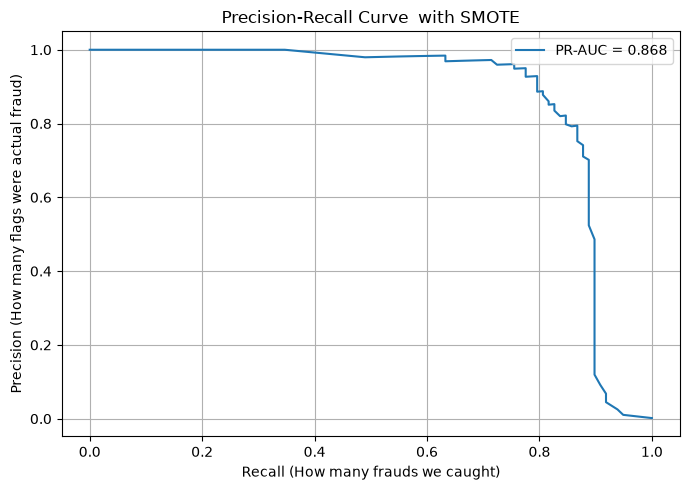

In [18]:
precision, recall, thresholds = precision_recall_curve(y_test, y_probs_smote)
pr_auc = auc(recall, precision)

print(f"Area Under Precision-Recall Curve  with SMOTE: {pr_auc:.4f}")

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel('Recall (How many frauds we caught)')
plt.ylabel('Precision (How many flags were actual fraud)')
plt.title('Precision-Recall Curve  with SMOTE')
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()

Area Under Precision-Recall with SMOTEENN: 0.8588


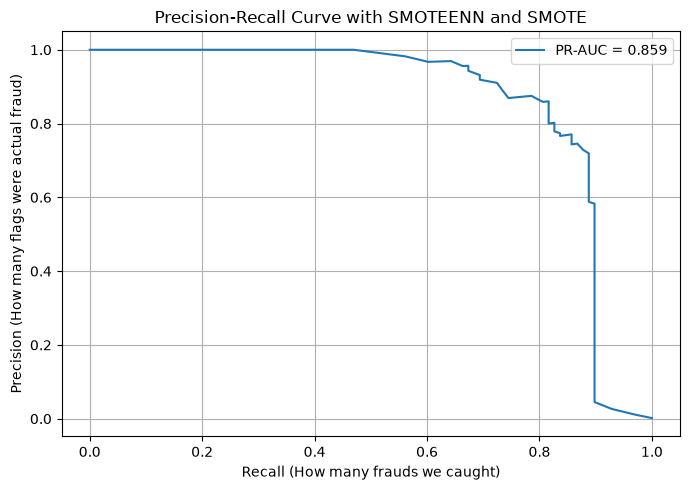

In [19]:
precision, recall, thresholds = precision_recall_curve(y_test, y_probs_smoteenn)
pr_auc = auc(recall, precision)

print(f"Area Under Precision-Recall with SMOTEENN: {pr_auc:.4f}")

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel('Recall (How many frauds we caught)')
plt.ylabel('Precision (How many flags were actual fraud)')
plt.title('Precision-Recall Curve with SMOTEENN and SMOTE')
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()

Area Under Precision-Recall with SMOTEENN and SMOTE: 0.8530


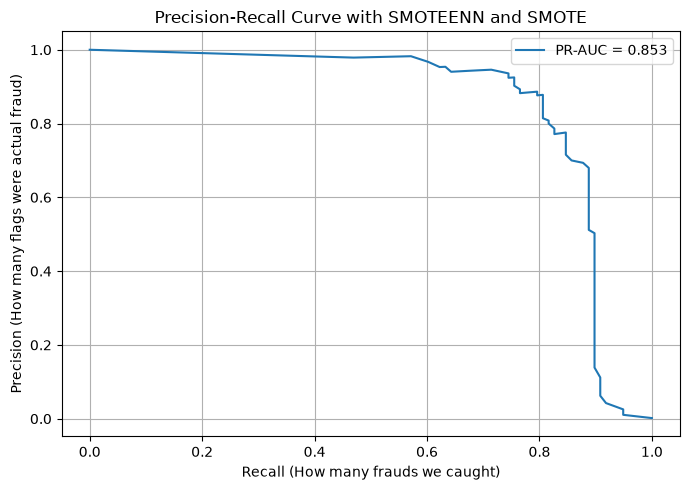

In [20]:
precision, recall, thresholds = precision_recall_curve(y_test, y_probs_smoteenn_smote)
pr_auc = auc(recall, precision)

print(f"Area Under Precision-Recall with SMOTEENN and SMOTE: {pr_auc:.4f}")

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel('Recall (How many frauds we caught)')
plt.ylabel('Precision (How many flags were actual fraud)')
plt.title('Precision-Recall Curve with SMOTEENN and SMOTE')
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()